# Stage 2: Initial Pilot (Zero-Shot Relevance Assessment)
This notebook evaluates the Qwen3.5-4B model on a small sample of TREC DL 2019 queries.
We will use this to generate our initial Risk vs. Coverage curve for the Stage 2 report.

In [1]:
import csv
import os
import pandas as pd
import json
import torch
import numpy as np
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
import ir_datasets
import yaml

# Load configuration
with open('../configs/default.yaml', 'r') as f:
    config = yaml.safe_load(f)

# Set random seed for reproducibility
torch.manual_seed(config.get('seed', 42))

## 1. Load the Pilot Data
We load the exported queries and qrels from our `data/` directory (created by `scripts/download_data.py`).

In [2]:
print("Loading official TREC DL 2019 qrels...")
qrels_path = "../data/trec_dl_2019/qrels.json"
qrels_df = pd.read_json(qrels_path)

# For the official Stage 2 Pilot, we use all available TREC DL 2019 evaluation queries
sample_query_ids = qrels_df['query_id'].unique()
qrels_df = qrels_df[qrels_df['query_id'].isin(sample_query_ids)].copy()

print("Fetching texts for pilot documents and queries...")
from datasets import load_dataset
# Bypass the empty local queries.json caused by the ir_datasets Windows crash.
# We pull the clean queries directly from the BeIR dataset.
queries_ds = load_dataset("BeIR/msmarco", "queries", split="queries")
queries_dict = dict(zip(queries_ds['_id'], queries_ds['text']))

# Add query text
qrels_df['query_text'] = qrels_df['query_id'].astype(str).map(queries_dict)

corpus_ds = load_dataset("BeIR/msmarco", "corpus", split="corpus")
pilot_doc_ids = set(qrels_df['doc_id'].astype(str).unique())

print("Optimizing memory mapping for Windows...")
all_ids = corpus_ds['_id']
indices = [i for i, doc_id in enumerate(all_ids) if doc_id in pilot_doc_ids]

pilot_corpus = corpus_ds.select(indices)
doc_mapping = dict(zip(pilot_corpus['_id'], pilot_corpus['text']))

qrels_df['doc_text'] = qrels_df['doc_id'].astype(str).map(doc_mapping)

# Drop any pairs that couldn't be matched
qrels_df = qrels_df.dropna(subset=['query_text', 'doc_text'])
print(f"Data ready! Total valid pairs for pilot: {len(qrels_df)}")

Loading official TREC DL 2019 qrels...
Fetching texts for pilot documents and queries...


Optimizing memory mapping for Windows...
Data ready! Total valid pairs for pilot: 9260


## 2. Load the Assessor Model (Qwen3.5-4B in 4-bit)

In [3]:
model_id = config["assessor"]["model_name"]

print(f"Loading {model_id} in 4-bit...")
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
)

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map={"":"cuda:0"},
    quantization_config=quantization_config,
    attn_implementation="sdpa",
)
print("Model loaded successfully!")

Loading Qwen/Qwen3.5-4B in 4-bit...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Model loaded successfully!


## 3. Build Prompt

In [4]:
def build_prompt(query: str, document: str) -> str:
    """
    Builds a zero-shot relevance assessment prompt.
    Since Qwen3.5-4B is a BASE model (not an Instruct/Chat model), 
    we MUST use a pure text completion format rather than a Chat Template.
    """
    prompt = (
        "You are an expert information retrieval evaluator.\n\n"
        f"Query: {query}\n\n"
        f"Document: {document}\n\n"
        "Is the document relevant to the query? Answer strictly with one word: 'Yes' or 'No'.\n\n"
        "Relevance (Yes/No):"
    )
    return prompt

## 4. Run Inference

In [7]:

csv_path = "../results/pilot_results/pilot_results.csv"
os.makedirs("../results/pilot_results", exist_ok=True)

if not os.path.exists(csv_path):
    with open(csv_path, 'w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['query_id', 'doc_id', 'true_relevance', 'prob_relevant', 'predicted_label'])

yes_token_id = tokenizer.encode("Yes", add_special_tokens=False)[0]
no_token_id = tokenizer.encode("No", add_special_tokens=False)[0]

# CRITICAL FIX FOR SPEED: We MUST use batched inference!
BATCH_SIZE = 8 # Process 16 documents at once

# Configure padding for batched inference
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

print(f"Running highly-optimized BATCHED inference (Batch Size: {BATCH_SIZE})...")

# OPTIMIZATION: Sort by text length to minimize padding overhead in batches
qrels_df['approx_len'] = qrels_df['query_text'].str.len() + qrels_df['doc_text'].str.len()
qrels_df = qrels_df.sort_values('approx_len')

# Group data into batches
all_rows = list(qrels_df.iterrows())
batches = [all_rows[i:i + BATCH_SIZE] for i in range(0, len(all_rows), BATCH_SIZE)]

with open(csv_path, 'a', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    for batch in tqdm(batches, total=len(batches)):
        batch_prompts = []
        for _, row in batch:
            prompt = build_prompt(row['query_text'], row['doc_text'])
            batch_prompts.append(prompt)
            
        # Tokenize the entire batch at once (padding up to the longest document in the batch)
        inputs = tokenizer(batch_prompts, padding=True, return_tensors="pt").to(model.device)
        
        with torch.no_grad():
            outputs = model(**inputs)
            # Extract the very last token's logits for each sequence in the batch
            next_token_logits = outputs.logits[:, -1, :]
            
            # Calculate probabilities for the entire batch instantly
            yes_logits = next_token_logits[:, yes_token_id]
            no_logits = next_token_logits[:, no_token_id]
            
            exp_yes = torch.exp(yes_logits)
            exp_no = torch.exp(no_logits)
            prob_yes = (exp_yes / (exp_yes + exp_no)).float().cpu().numpy()
            
        preds = (prob_yes > 0.5).astype(int)
        
        # Save the batch to disk instantly
        for i, (_, row) in enumerate(batch):
            writer.writerow([row['query_id'], row['doc_id'], row['relevance'], prob_yes[i], preds[i]])
        f.flush()

print("Batched inference complete!")

Running highly-optimized BATCHED inference (Batch Size: 8)...


  0%|          | 0/1158 [00:00<?, ?it/s]

RuntimeError: CUDA error: out of memory
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


## 5. Initial Coverage vs. Risk Analysis


 --- Pilot Results Snapshot (7224 documents) --- 
Total Base Risk: 20.03%


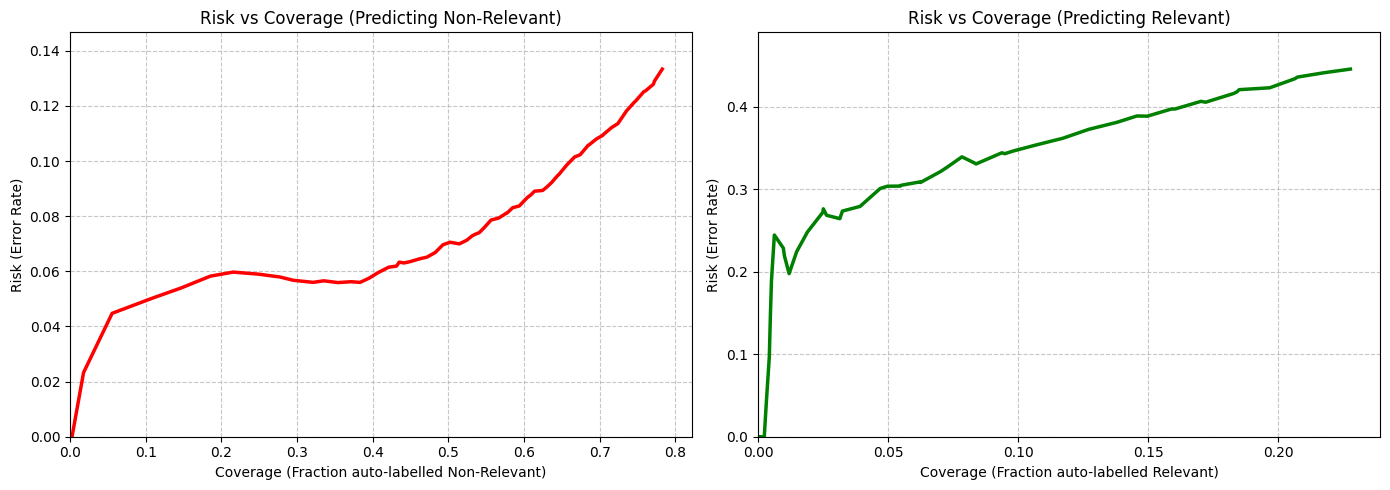

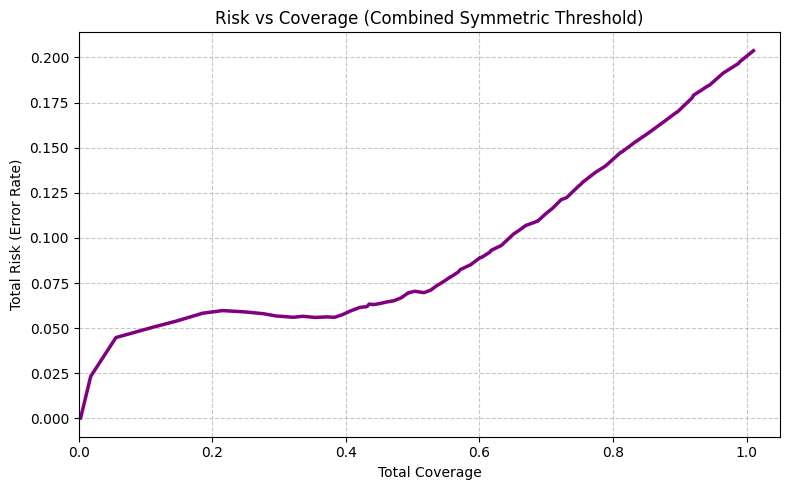

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Create directories for saving figures
os.makedirs('../results/figures', exist_ok=True)

# Load the data processed so far
results_df = pd.read_csv('../results/pilot_results/pilot_results.csv')

# Calculate true binary relevance
results_df['true_binary'] = (results_df['true_relevance'] >= 2).astype(int)

# 1. Curve for predicting NON-RELEVANT (prob_relevant <= 1 - t)
thresholds_neg = np.linspace(0.5, 0.999, 100)
cov_neg, risk_neg = [], []

for t in thresholds_neg:
    mask = results_df['prob_relevant'] <= (1 - t)
    coverage = mask.mean()
    error = (results_df.loc[mask, 'true_binary'] == 1).mean() if coverage > 0 else 0.0
    cov_neg.append(coverage)
    risk_neg.append(error)

# 2. Curve for predicting RELEVANT (prob_relevant >= t)
thresholds_pos = np.linspace(0.5, 0.999, 100)
cov_pos, risk_pos = [], []

for t in thresholds_pos:
    mask = results_df['prob_relevant'] >= t
    coverage = mask.mean()
    error = (results_df.loc[mask, 'true_binary'] == 0).mean() if coverage > 0 else 0.0
    cov_pos.append(coverage)
    risk_pos.append(error)

print(f"\n --- Pilot Results Snapshot ({len(results_df)} documents) --- ")
print(f"Total Base Risk: {(results_df['predicted_label'] != results_df['true_binary']).mean():.2%}")

# PLOT 1: Separate Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Non-Relevant Subplot
axes[0].plot(cov_neg, risk_neg, '-', color='red', linewidth=2.5)
axes[0].set_title('Risk vs Coverage (Predicting Non-Relevant)')
axes[0].set_xlabel('Coverage (Fraction auto-labelled Non-Relevant)')
axes[0].set_ylabel('Risk (Error Rate)')
axes[0].grid(True, linestyle='--', alpha=0.7)
if max(cov_neg) > 0: axes[0].set_xlim(0, max(cov_neg) * 1.05)
if max(risk_neg) > 0: axes[0].set_ylim(0, max(risk_neg) * 1.1)

# Relevant Subplot
axes[1].plot(cov_pos, risk_pos, '-', color='green', linewidth=2.5)
axes[1].set_title('Risk vs Coverage (Predicting Relevant)')
axes[1].set_xlabel('Coverage (Fraction auto-labelled Relevant)')
axes[1].set_ylabel('Risk (Error Rate)')
axes[1].grid(True, linestyle='--', alpha=0.7)
if max(cov_pos) > 0: axes[1].set_xlim(0, max(cov_pos) * 1.05)
if max(risk_pos) > 0: axes[1].set_ylim(0, max(risk_pos) * 1.1)

plt.tight_layout()
plt.savefig('../results/figures/risk_coverage_separate.png', dpi=150)
plt.show()

# PLOT 2: Combined Curve
cov_combined = np.array(cov_neg) + np.array(cov_pos)
risk_combined = np.zeros_like(cov_combined)
for i in range(len(cov_combined)):
    if cov_combined[i] > 0:
        risk_combined[i] = (risk_neg[i] * cov_neg[i] + risk_pos[i] * cov_pos[i]) / cov_combined[i]

plt.figure(figsize=(8, 5))
plt.plot(cov_combined, risk_combined, '-', color='purple', linewidth=2.5)
plt.title('Risk vs Coverage (Combined Symmetric Threshold)')
plt.xlabel('Total Coverage')
plt.ylabel('Total Risk (Error Rate)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0, 1.05)
plt.tight_layout()
plt.savefig('../results/figures/risk_coverage_combined.png', dpi=150)
plt.show()
